In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
np.random.seed(42)
p = 0.30
sample_size = 20

Generate outcomes for 20 customers

In [3]:
samples = np.random.binomial(n=1, p=p, size=sample_size)
print(samples)

[0 1 1 0 0 0 0 1 0 1 0 1 1 0 0 0 0 0 0 0]


Count clicks and non-clicks

In [4]:
number_of_clicks = np.sum(samples == 1)
number_of_non_clicks = np.sum(samples == 0)
print("Number of clicks:", number_of_clicks)
print("Number of non-clicks:", number_of_non_clicks)

Number of clicks: 6
Number of non-clicks: 14


Calculate the empirical PMF

In [5]:
emp_p0 = number_of_non_clicks / sample_size
emp_p1 = number_of_clicks / sample_size

Plot empirical and theoretical expectation

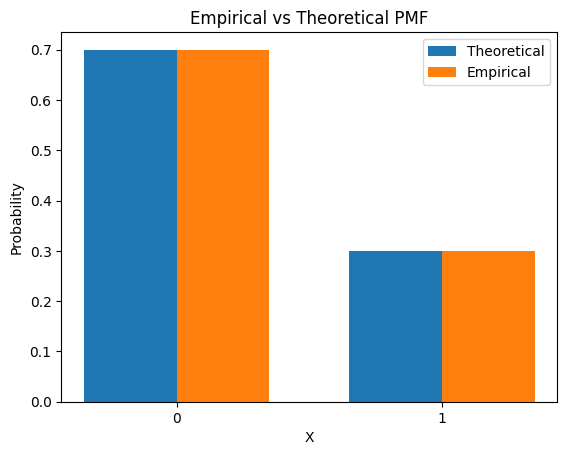

In [7]:
x = np.array([0, 1])
theo = [1 - p, p]
emp = [emp_p0, emp_p1]
w = 0.35
plt.bar(x - w/2, theo, w, label="Theoretical")
plt.bar(x + w/2, emp, w, label="Empirical")

plt.xticks(x)
plt.xlabel("X")
plt.ylabel("Probability")

plt.title("Empirical vs Theoretical PMF")

plt.legend();

plt.show()

Calculate the theoretical expectation

In [13]:
theo_mean = p       # E[X] = p
print(theo_mean)

0.3


Calculate the empirical expectation

In [11]:
emp_mean = np.mean(samples)
print(emp_mean)

0.3


 Calculate the theoretical variance

In [14]:
theo_var = p * (1 - p)    # Var(X) = p(1- p)
print(theo_var)

0.21


Calculate the empirical variance

In [16]:
emp_var = np.var(samples)
print(emp_var)

0.20999999999999996


Final result table

In [19]:
table = pd.DataFrame({
    "Measure": ["P(X=0)", "P(X=1)", "Expectation", "Variance"],
    "Theoretical": [1 - p, p, theo_mean, theo_var],
    "Empirical": [emp_p0, emp_p1, emp_mean, emp_var]
})

table["Absolute difference"] = (table["Theoretical"] - table["Empirical"]).abs()

print(table.round(4))

       Measure  Theoretical  Empirical  Absolute difference
0       P(X=0)         0.70       0.70                  0.0
1       P(X=1)         0.30       0.30                  0.0
2  Expectation         0.30       0.30                  0.0
3     Variance         0.21       0.21                  0.0


Effect of sample size

In [20]:
rows = []
for n in [10, 100, 1000, 10000]:
    s = np.random.binomial(1, p, n)
    rows.append([n, np.mean(s == 0), np.mean(s == 1), s.mean(), s.var()])
print(pd.DataFrame(rows, columns=["Sample size", "Emp P(X=0)", "Emp P(X=1)", "Emp mean", "Emp variance"]))


   Sample size  Emp P(X=0)  Emp P(X=1)  Emp mean  Emp variance
0           10      0.9000      0.1000    0.1000      0.090000
1          100      0.6600      0.3400    0.3400      0.224400
2         1000      0.7060      0.2940    0.2940      0.207564
3        10000      0.7093      0.2907    0.2907      0.206194
